In [1]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

In [2]:
data = pd.read_csv("C:/Users/Edunet Foundation/Downloads/Methodist_AI/Wholesale_customers_data.csv")
data.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [ ]:
# NULL
data.isnull().sum()

In [4]:
data.duplicated().sum()

np.int64(0)

In [ ]:
data.describe()

In [ ]:
data.info()

In [ ]:
data.shape

In [8]:
# Standardization
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [ ]:
interm = scaler.fit_transform(data)
interm

In [ ]:
# convert back into dataframe
data = pd.DataFrame(interm, data.index, data.columns)
data.head()

In [11]:
km = KMeans(n_clusters=2, init='k-means++')
km.fit(data)

,n_clusters,2
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


In [12]:
# WSS-> within cluster sum of squared Error
km.inertia_

2600.3756482224426

In [13]:
WSS = []
for k in range(1, 21):
    kmeans = KMeans(n_clusters=k, init='k-means++')
    kmeans.fit(data)
    WSS.append(kmeans.inertia_)

In [ ]:
df = pd.DataFrame({'k': range(1, 21),
                   'WSS': WSS})
df.head(20)

In [16]:
import matplotlib.pyplot as plt

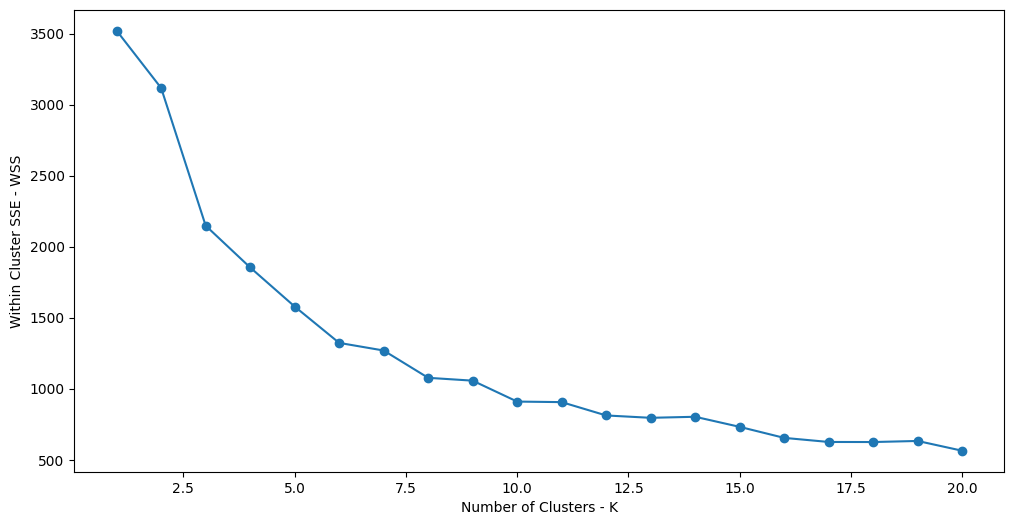

In [17]:
plt.figure(figsize=(12, 6))
plt.plot(df['k'], df['WSS'], marker='o')
plt.xlabel('Number of Clusters - K')
plt.ylabel('Within Cluster SSE - WSS')
plt.show()

In [18]:
# optimal k = 6
km = KMeans(n_clusters=6, random_state=42)
clusters = km.fit_predict(data)

In [ ]:
data.head()

In [20]:
frame = pd.DataFrame(data)
frame['Prediction'] = clusters
frame['Prediction'].value_counts()

Prediction
1    200
0     94
3     91
2     36
4     14
5      5
Name: count, dtype: int64

In [22]:
# plotting a 8-columned vector --- in 2D 
# --reduce it to 2 columns using PCA

from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(data)  # 2 columns

In [ ]:
X_pca

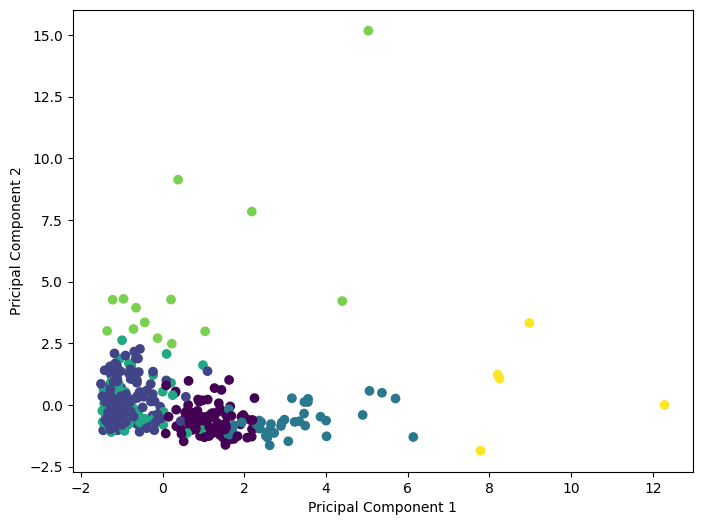

In [25]:
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1],
            c = clusters, cmap='viridis')
plt.xlabel('Pricipal Component 1')
plt.ylabel('Pricipal Component 2')
plt.show()